# Entropy-Regularized SPMD

## Problems

Both problems are the team's environments (`ie692_rl.envs`), imported
here, not copied, so this notebook always uses the same rules as the baseline. Both are written with
**costs** (lower is better) and discount factor γ = 0.9.

Each environment provides `n_states`, `n_actions`, `gamma` and `step_one(state, action, rng)` returning
`(next_state, cost, done)`, which is everything the team's online estimator needs to sample Q.

In [1]:
from pathlib import Path

import numpy as np

from ie692_rl.envs import Blackjack, GridWorld

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
rng = np.random.default_rng(0)

### GridWorld

10 × 10 board, start in the top-left square (S = 0). Actions: up, down, left, right. The intended move
happens with probability 0.8; otherwise one of the other three directions is taken. Walls clip
movement. Each move costs 0.2 from an ordinary square, 1.0 from a hazard (H) and 0 from a goal (G).
From a goal or hazard the agent is sent back to the start with probability 0.8. Runs never
terminate, so the agent should reach a goal while avoiding hazards.

In [2]:
gridworld = GridWorld()
print(
    f"states: {gridworld.n_states}, actions: {gridworld.n_actions} {gridworld.action_names}, gamma: {gridworld.gamma}"
)
print(gridworld.board())

# One sampled step from the start for each action: (next state, cost, done).
states = gridworld.initial_states(4, rng)
next_states, costs, done = gridworld.step(states, np.arange(4), rng)
print(
    "\nfrom the start:",
    [(name, int(s), float(c)) for name, s, c in zip(gridworld.action_names, next_states, costs, strict=True)],
)

states: 100, actions: 4 ('up', 'down', 'left', 'right'), gamma: 0.9
S . . . . . . . . G
. . H . . . . H . .
. . . . H . . . . .
. . . . . . H . . .
. . . H . . . . . .
. . . . . . . . H .
. . H . . . . . . .
. . . . . H . . . .
. H . . . . . H . .
G . . . . . . . . G



from the start: [('up', 0, 0.2), ('down', 10, 0.2), ('left', 0, 0.2), ('right', 1, 0.2)]


### Blackjack

Simplified game from the project handout: cards 2–5 with equal probability, no aces. A state is
(player total 4–11, dealer's visible card 2–5), so 32 states. Actions: stop (0) or draw (1). Going
above 11 is a bust. When the player stops, the dealer draws until reaching 9 or more. Terminal cost:
win −1, draw 0, loss +1. Every episode starts from the fixed hand (total 8, dealer shows 3).

In [3]:
blackjack = Blackjack()
start = int(blackjack.encode(blackjack.evaluation_total, blackjack.evaluation_dealer))
print(
    f"states: {blackjack.n_states}, actions: {blackjack.n_actions} {blackjack.action_names}, gamma: {blackjack.gamma}"
)
print(f"start state: {start} = (total {blackjack.evaluation_total}, dealer {blackjack.evaluation_dealer})")

# Ten sampled "stop" moves from the start: the dealer plays out, cost -1 win / 0 draw / +1 loss.
states = blackjack.initial_states(10, rng)
_, costs, done = blackjack.step(states, np.zeros(10, dtype=int), rng)
print("stop from the start, 10 samples:", costs.astype(int).tolist(), "done:", bool(done.all()))

states: 32, actions: 2 ('stop', 'draw'), gamma: 0.9
start state: 17 = (total 8, dealer 3)
stop from the start, 10 samples: [1, -1, 1, -1, 1, -1, 1, 1, 1, 1] done: True


## Online validation: baseline SPMD vs Entropy-Regularized SPMD

Every method learns from **online sampling** with the team's policy evaluation baseline,
**Truncated On-Policy Monte Carlo with dynamic exploration time** (`ie692_rl.core.TOMC`). The baseline and
the enhancement differ only in the policy update.

- **Estimator (`TOMC`):** each iteration starts a fresh stream from the start state (blackjack deals a new
  hand after each finished one) and follows the current policy until every pair with π(a|s) ≥ (1−γ)/|A|
  has been tried and the discounted tail after the last first visit is below `bias` = 0.01. Q(s, a) is the
  return after the first visit to (s, a); rarer pairs get the pessimistic cost 1/(1−γ) = 10.
- **Baseline SPMD:** the team's KL step, π ∝ π exp(−ηQ), which is the entropy-regularized step with τ = 0.
- **Entropy-Regularized SPMD:** π ∝ π^{1/(1+ητ)} exp(−ηQ/(1+ητ)) with τ > 0. Each sampled cost includes
  τ Σ_a π(a|s) log π(a|s), so the sampled Q is the regularized Q.

**Protocol**

1. **Sweep** (10% of the full budget, 100 seeds, 1000–1099): τ ∈ {0.001, 0.01, 0.1}, step size η ∈ {1, 10, 100}
   and rollouts M ∈ {1, 4, 16}, plus τ = 0 (the baseline). A rollout is one TOMC estimate; with M rollouts,
   Q is their average, and all of them count against the budget.
2. **Choice:** the smallest mean gap with M = 1 (the handout's method), among settings where every seed made
   at least one update.
3. **Full runs** (20M steps on GridWorld, 120k on Blackjack; 20 fresh seeds, 200–219) of the chosen settings.

The score is the exact gap to the optimal cost from the start state (0 = optimal). It is computed from the
model and is used here for choosing settings and reporting; the learners only see samples.

In [4]:
import sys
import tempfile

sys.path.insert(0, str(REPO / "benchmarks"))  # the sweep script; its functions are reused here
from IPython.display import Image, display

import param_sweep as sweep
from ie692_rl.experiment import (
    Job,
    default_workers,
    gap_curve,
    int_list,
    load_config,
    map_jobs,
    method_label,
    problem_budget,
)

%matplotlib inline

CONFIG_PATH = REPO / "config.cfg"
CONFIG = load_config(CONFIG_PATH)
BUDGET_SCALE = 0.1  # the sweep's share of the full budget
SWEEP_SEEDS = range(sweep.FIRST_SEED, sweep.FIRST_SEED + 100)
TEST_SEEDS = int_list(CONFIG["tuning"]["test_seeds"])
BUDGETS = {name: problem_budget(CONFIG, name) for name in sweep.PROBLEMS}

### Hyperparameter sweep

In [5]:
sweep_runs = sweep.run_jobs(
    [
        (name, tau, eta, m, seed, round(BUDGET_SCALE * BUDGETS[name]))
        for name in sweep.PROBLEMS
        for tau in (0.0, *sweep.TAUS)
        for eta in sweep.STEP_SIZES
        for m in sweep.ROLLOUTS
        for seed in SWEEP_SEEDS
    ],
    default_workers(),
)
grid = sweep.aggregate(sweep_runs)  # one row per combination

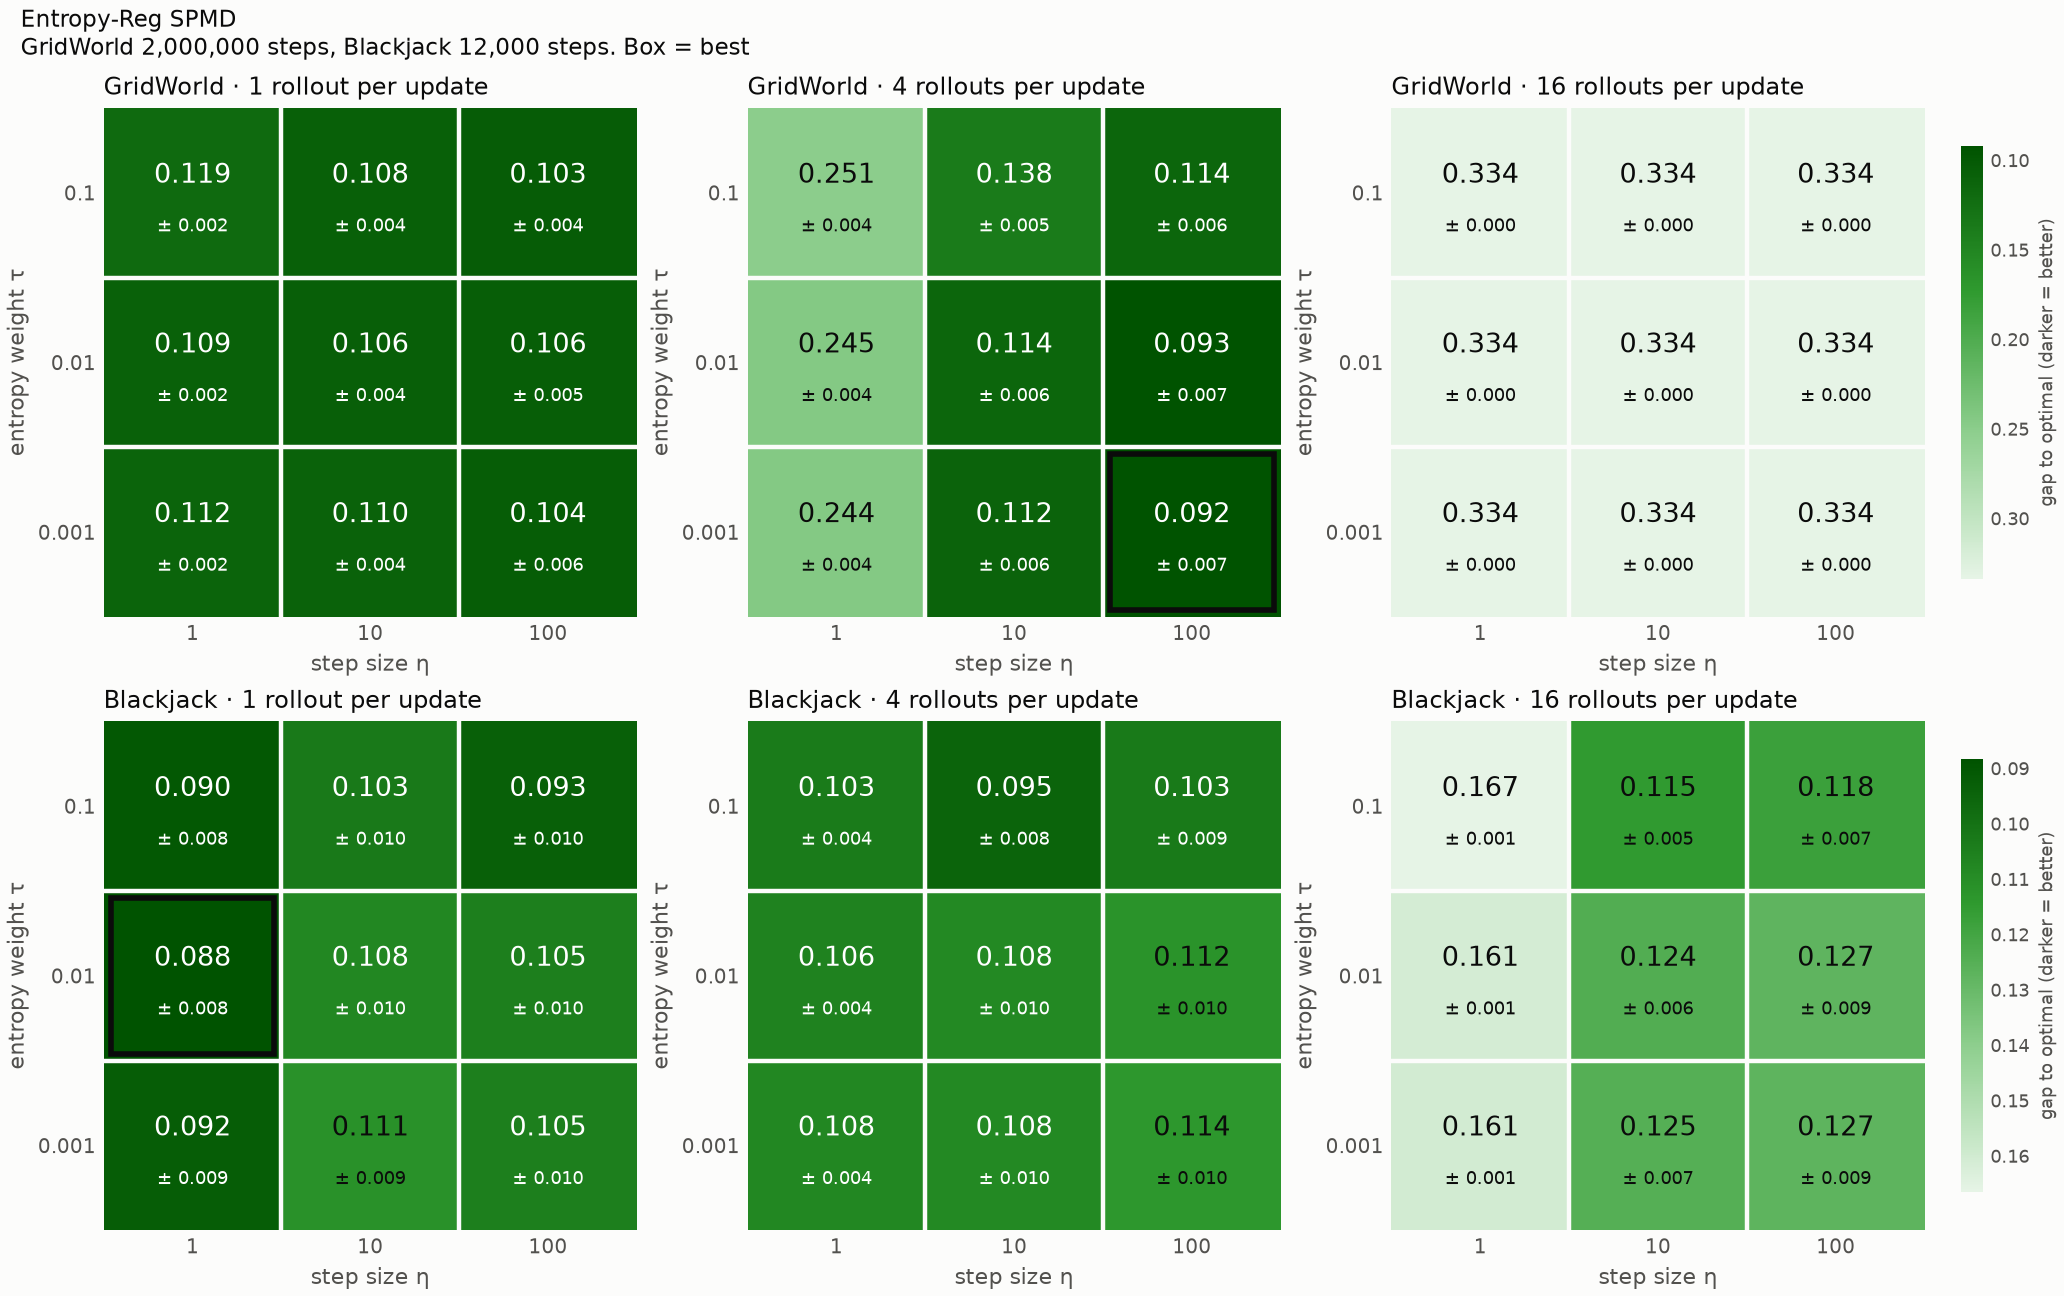

In [6]:
with tempfile.TemporaryDirectory() as folder:
    path = Path(folder) / "joint_heatmap.png"
    sweep.heatmaps(grid, sweep_runs, sweep.ROLLOUTS, path, brief=True)
    display(Image(filename=str(path), width=1000))

### Learning curves

In [7]:
def choose(name, entropy):
    """Best M = 1 setting of one method, among those where every seed made an update."""
    eligible = [
        r
        for r in grid
        if r["problem"] == name
        and r["rollouts"] == 1
        and (r["tau"] > 0) == entropy
        and r["no_update_seeds"] == 0
    ]
    return min(eligible, key=lambda r: r["mean_gap"])


chosen = {
    (name, method): choose(name, entropy=method == "entropy_reg")
    for name in sweep.PROBLEMS
    for method in ("baseline", "entropy_reg")
}

In [8]:
jobs = []
for (name, method), r in chosen.items():
    params = {"estimator.bias": sweep.BIAS, "spmd.step_size": r["step_size"]}
    if r["tau"] > 0:
        params["spmd.tau"] = r["tau"]
    jobs += [
        Job(str(CONFIG_PATH), name, method, tuple(sorted(params.items())), seed, BUDGETS[name])
        for seed in TEST_SEEDS
    ]
results = map_jobs(jobs, default_workers())

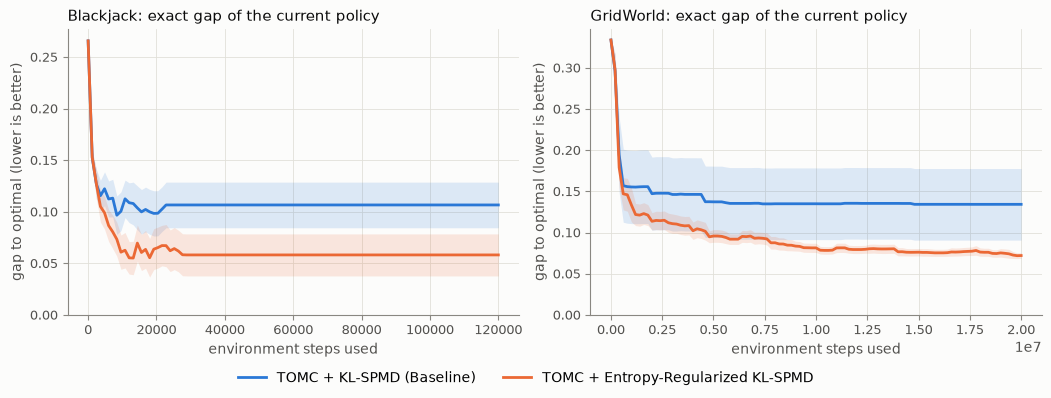

In [9]:
import matplotlib.pyplot as plt

COLORS = {"baseline": "#2a78d6", "entropy_reg": "#eb6834"}
SURFACE, INK, INK_SECONDARY, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
points = np.linspace(0, 1, 101)  # fractions of the budget

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.9), layout="constrained", facecolor=SURFACE)
for ax, name in zip(axes, ("Blackjack", "GridWorld"), strict=True):
    for method, color in COLORS.items():
        curves = np.array(
            [
                gap_curve(results[job], job.budget, points)
                for job in jobs
                if (job.problem, job.method) == (name, method)
            ]
        )
        mean, se = curves.mean(axis=0), curves.std(axis=0, ddof=1) / np.sqrt(len(curves))
        x = points * BUDGETS[name]
        ax.fill_between(x, mean - se, mean + se, color=color, alpha=0.15, linewidth=0)
        ax.plot(x, mean, color=color, linewidth=2, label=method_label(CONFIG, method))
    ax.set_facecolor(SURFACE)
    ax.grid(color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelcolor=INK_SECONDARY, labelsize=9)
    ax.set_title(f"{name}: exact gap of the current policy", loc="left", fontsize=11, color=INK)
    ax.set_xlabel("environment steps used", color=INK_SECONDARY)
    ax.set_ylabel("gap to optimal (lower is better)", color=INK_SECONDARY)
    ax.set_ylim(bottom=0)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()